# Question 1: Can a student's other reasons predict whether the course was mandatory?

**The question:** Can we predict, from a student's *other* reasons for taking the course, whether they ticked **"This was mandatory for me"**?

- **Type of problem:** binary classification. The **label** is `mandatory` (1 or 0).
- **Data:** our own copy of the cleaned dataset (`dataminers_cleaner_v2.csv`). In it, "The other courses were even less attractive" has its own column (`less_attractive`) and no longer counts as mandatory.
- **Good to know before we start:** everyone had to tick at least one reason. If a student ticked no other reason, "mandatory" is the only one left. So part of any pattern comes from how the form works, and the dataset is small (133 students after filtering).

**Steps:** 1 load, 2 filter rows, 3 features and label, 4 split, 5 baseline, 6 logistic regression, 7 confusion matrix, 8 k-NN, 9 choosing k.

## Step 1: Load the data

`read_csv` reads the file into a table (dataframe). `df.shape` gives **(rows, columns)**.

- We get **(222, 15)**: 222 rows (students) and 15 columns (survey questions).

In [ ]:
import pandas as pd

df = pd.read_csv("/Users/hanshornbek/Documents/ITU/3. Semester/Data Mining/DAMML-group -project/Assignment 01/Assignment #01 (Dataset)/cleaned/dataminers_cleaner_v2.csv")
df.shape

## Step 2: Filtering Rows

We keep only the rows we want to work with: **Software Design students from 2020-2025**.

- **Why only Software Design?** Students from other programmes have freely chosen the course as an elective. 
- **Why not 2026?** This year students can choose freely. Including it would hide the pattern.
- The shape is now **(133, 15)**, so we have 133 students.

This step removes *rows*. Removing *columns* comes in Step 3.

In [ ]:
df = df[(df["programme_clean"] == "Software Design") & (df["response_year"] < 2026)]
df.shape

## Step 3: Feature Selection

- **Label (`y`)**: the column we want to predict, `mandatory` (1 = mandatory, 0 = not).
- **Features (`X`)**: the columns the model learns from, here the four motives: `exciting`, `commercial_skills`, `uncertain`, `less_attractive`.

**Why not put in more columns?** A column with no real link to the label would give the model one more chance to find a *coincidence* in the data, a pattern that looks real but is only chance. With just 133 students, the model can learn such coincidences as if they were rules (**overfitting**), and they fail on new students. So we only include columns that we have a reason to include.

Columns we decided **not** to include:

- `why`: the raw text that the label comes from
- `seattle`: messy answers
- time of day and timestamps: they mostly stand in for the year
- height and shoe size: not part of this question

**No encoding or scaling is needed**, because the four columns are already 0/1.

`value_counts()` shows how balanced the label is: **78 not mandatory (0)** and **55 mandatory (1)**.

In [ ]:
features = ["exciting", "commercial_skills", "uncertain", "less_attractive"]

X = df[features]
y = df["mandatory"]

y.value_counts()

## Step 4: Splitting the Data

A model must be tested on students it has **not seen**. Otherwise we only measure how well it memorised the training data. So we split the data:

- **80% training data**: the model learns from these students.
- **20% test data**: we compare the model's guesses with the real answers.

Two settings:

- `random_state=42`: the same random split every time the code runs.
- `stratify=y`: the share of mandatory students is the same in both parts.

We get **106 training** and **27 test** students. 

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

## Step 5: Baseline

A **baseline** is the simplest possible "model": always guess the most common class, here *not mandatory*.

Its accuracy is the share of test students who are not mandatory = **0.59**.

Our model has to beat this number. 

In [ ]:
print("Baseline accuracy:", (y_test == 0).mean())

## Step 6: Logistic regression

Logistic regression turns the features into a **probability** that the student is mandatory (using the sigmoid function), and predicts *mandatory* when that probability is at least 0.5.

- `fit` lets the model learn from the training students only.
- `predict` makes it guess for the test students.
- `accuracy_score` is the share of correct guesses.

**Result: 0.67**, which is 18 of 27 correct. That is only 2 students more than the baseline. 

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

## Step 7: Confusion matrix

The confusion matrix sorts the model's guesses into four boxes. 

The diagonal (12 and 6) is the model being right. The other two boxes are the false predictions.



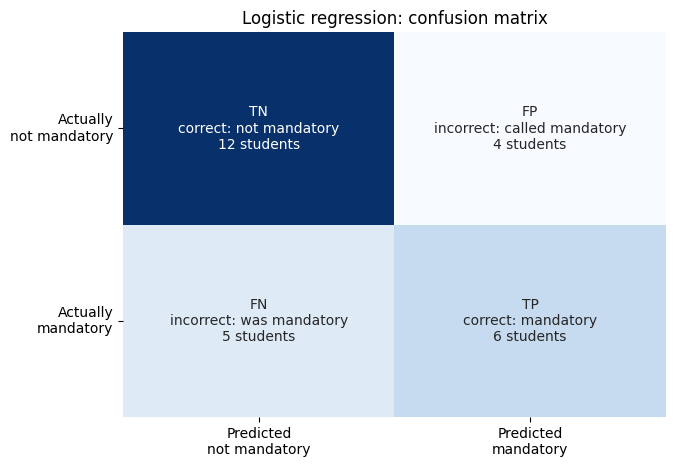

In [53]:
# Each box shows its name (TN, FP, FN, TP), what it means and the number of students.
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

# the text written in each of the four boxes
text = [
    [f"TN\ncorrect: not mandatory\n{cm[0][0]} students", f"FP\nincorrect: called mandatory\n{cm[0][1]} students"],
    [f"FN\nincorrect: was mandatory\n{cm[1][0]} students", f"TP\ncorrect: mandatory\n{cm[1][1]} students"],
]

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=text, fmt="", cmap="Blues", cbar=False,
            xticklabels=["Predicted\nnot mandatory", "Predicted\nmandatory"],
            yticklabels=["Actually\nnot mandatory", "Actually\nmandatory"])
plt.yticks(rotation=0)
plt.title("Logistic regression: confusion matrix")
plt.show()

### Metrics from the confusion matrix

All four metrics can be calculated from the four boxes. We use .accuracy_score() and .classification_report(), to get these metrics. 

| Metric | Formula | Question it answers |
|---|---|---|
| Accuracy | (TP + TN) / all | How many guesses were right? |
| Precision | TP / (TP + FP) | When the model says mandatory, how often is it right? |
| Recall | TP / (TP + FN) | Of the truly mandatory students, how many did it find? |
| F1 | 2 * (precision * recall / precision + recall) | One number that balances precision and recall |


In [57]:
from sklearn.metrics import accuracy_score, classification_report
# Read the four boxes out of the confusion matrix (rows = actual, columns = predicted).
print("Logistic Regression accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Logistic Regression accuracy: 0.6666666666666666
              precision    recall  f1-score   support

           0       0.71      0.75      0.73        16
           1       0.60      0.55      0.57        11

    accuracy                           0.67        27
   macro avg       0.65      0.65      0.65        27
weighted avg       0.66      0.67      0.66        27



- **Accuracy 0.67:** 18 of 27 test students were classified correctly. The baseline gets 0.59, so the model is only 2 students better.
- **Precision 0.60:** when the model says "mandatory", it is right 6 times out of 10.
- **Recall 0.55:** it finds 6 of the 11 truly mandatory students and misses 5.
- **F1 0.57:** a balance of the two. Both are middling, so F1 is too.

## Step 8: k-NN

We want to run the experiment with another model to see if we get different results. 
For each test student, k-NN finds the **k most similar training students** (closest in feature space) and takes their **majority label**. We use **k = 5**, as in the slides. **k** is a *hyperparameter*: we set it ourselves, the model does not learn it.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

print("k-NN accuracy:", accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn)) ## This is based on the same input as the confusion matrix. 

k-NN accuracy: 0.7777777777777778
              precision    recall  f1-score   support

           0       0.73      1.00      0.84        16
           1       1.00      0.45      0.62        11

    accuracy                           0.78        27
   macro avg       0.86      0.73      0.73        27
weighted avg       0.84      0.78      0.75        27



**Result:** accuracy **0.78** (21 of 27). For the mandatory class: precision **1.00**, recall **0.45**.

- When k-NN says "mandatory" it is always right (5 of 5), but it finds only 5 of the 11 truly mandatory students. 

k-NN scores higher on accuracy and F1, but that is 3 more students out of 27 on a single split. It is not strong evidence.

### Choosing different k's

 A small k can **overfit** (it follows single odd points), a large k can **underfit** (it ignores the pattern). We compare accuracy on the training students with accuracy on the test students. Odd k values avoid tied votes.

**Result:** the accuracy barely changes (train 0.79-0.81, test 0.78 for every k).

- **Few different students:** with only four 0/1 columns there are at most 16 possible combinations. Many students have identical answers, so their nearest neighbours are copies of them, and k hardly matters.
- **Training accuracy at k=1 is only 0.81, not close to 1.00.** Some students have identical answers but different labels, and no model can separate them. About 80% is close to the ceiling for these four columns.
- **Train and test are close**, so there is no sign of overfitting or underfitting.
- **The exact numbers at the extremes (k = 1 and k = 21) can differ a little between computers and library versions.** Many students are identical, so the tie among equally close neighbours is broken arbitrarily. The pattern (about 0.7-0.8 accuracy, never near 1.00 on training data) stays the same.

There is nothing to tune, so we keep k = 5.

In [47]:
for k in [1, 3, 5, 7, 9, 11, 15, 21]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    print(k, "train:", round(knn.score(X_train, y_train), 2),
             "test:", round(knn.score(X_test, y_test), 2))

1 train: 0.81 test: 0.78
3 train: 0.81 test: 0.78
5 train: 0.79 test: 0.78
7 train: 0.79 test: 0.78
9 train: 0.79 test: 0.78
11 train: 0.79 test: 0.78
15 train: 0.79 test: 0.78
21 train: 0.79 test: 0.78


## Conclusion

**Question:** Can a student's other reasons for taking the course predict whether they ticked "This was mandatory for me"?

**Answer:** Only a little. The motives carry some information, but not enough for a useful predictor.

| | Baseline | Logistic regression | k-NN (k=5) |
|---|---|---|---|
| Accuracy | 0.59 | 0.67 | 0.78 |
| Precision (mandatory) | - | 0.60 | 1.00 |
| Recall (mandatory) | - | 0.55 | 0.45 |
| F1 (mandatory) | - | 0.57 | 0.62 |

- Both models beat the baseline, but only by a few students out of 27, so we cannot say the difference is real.
- **Logistic regression**: finds slightly more of the mandatory students (recall 0.55) but calls some students mandatory by mistake (precision 0.60).
- **k-NN**: Whenever it says "mandatory" it is right (precision 1.00), but it misses more than half of the truly mandatory students (recall 0.45).
- Which model is "better" depends on which mistake is worse: missing a mandatory student (choose recall) or flagging a student wrongly (choose precision).
- The value of k hardly mattered.

**Our intepretation why the guess in limited**

- **Small data:** only 133 students, and just 27 in the test set. One student is worth about 3.7 percentage points, so the scores depend a lot on which students end up in the test set. 
- **Only four 0/1 features:** there are at most 16 different combinations of answers. Some students may have identical answers but different labels, so no model can separate them. 
- **The form itself:** everyone had to tick at least one reason. A student who ticked no other motive must have ticked "mandatory", so part of the pattern comes from how the question was asked, not from the students.

* Maybe we ran into the Multilabel classification problem here ?